<a href="https://colab.research.google.com/github/subhamswagatmohapatra-cmd/AML-LAB-/blob/main/AML_Experiment_4ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Gradient Descent Implementation and Visualization (3 Iterations)

This section re-runs the gradient descent algorithm for the linear regression model `y = wx + b` using the same dataset and learning rate, but this time for only 3 epochs. This will highlight the initial adjustments of the model parameters.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Given dataset
x = np.array([1, 2, 3])
y = np.array([2, 4, 5])

# Initial parameters (re-initialize for new run)
w = 0.0
b = 0.0

# Learning rate
learning_rate = 0.01

# Number of epochs for this run
epochs_new = 2

print(f"Initial parameters: w={w}, b={b}")

Initial parameters: w=0.0, b=0.0


Now, we'll re-implement the gradient descent loop for these 3 epochs. We'll track the parameter and loss history to visualize the learning process over this short duration.

In [ ]:
# Function to make predictions (re-define for clarity, though it's the same)
def predict(x_data, w_val, b_val):
    return w_val * x_data + b_val

# Mean Squared Error loss function (re-define for clarity)
def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

# Store history for visualization
w_history_new = []
b_history_new = []
loss_history_new = []

# Gradient Descent loop for 3 epochs
for epoch in range(epochs_new):
    # Make predictions
    y_pred = predict(x, w, b)

    # Calculate loss
    loss = mse_loss(y, y_pred)
    loss_history_new.append(loss)

    # Calculate gradients
    dw = -2 * np.mean(x * (y - y_pred))
    db = -2 * np.mean(y - y_pred)

    # Update parameters
    w = w - learning_rate * dw
    b = b - learning_rate * db

    w_history_new.append(w)
    b_history_new.append(b)

    print(f"Epoch {epoch+1}/{epochs_new}, Loss: {loss:.4f}, w: {w:.4f}, b: {b:.4f}")

print(f"\nFinal parameters after {epochs_new} epochs: w={w:.4f}, b={b:.4f}")

Epoch 1/2, Loss: 15.0000, w: 0.1667, b: 0.0733
Epoch 2/2, Loss: 11.8683, w: 0.3148, b: 0.1385

Final parameters after 2 epochs: w=0.3148, b=0.1385


Let's visualize the regression line's movement and the loss reduction over these first 3 iterations. You'll notice the changes are more pronounced compared to the subtle shifts after many epochs.

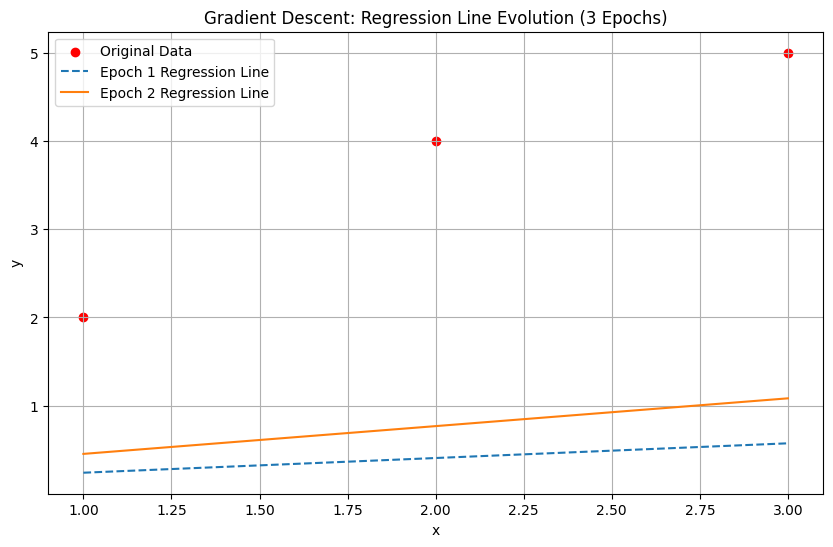

In [ ]:
# Visualize the regression line's progression for 3 epochs
plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='red', label='Original Data')

# Plot initial line (Epoch 1)
plt.plot(x, predict(x, w_history_new[0], b_history_new[0]), label='Epoch 1 Regression Line', linestyle='--')

# Plot subsequent lines
for i in range(1, epochs_new):
    plt.plot(x, predict(x, w_history_new[i], b_history_new[i]), label=f'Epoch {i+1} Regression Line', linestyle='-')

plt.title('Gradient Descent: Regression Line Evolution (3 Epochs)')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

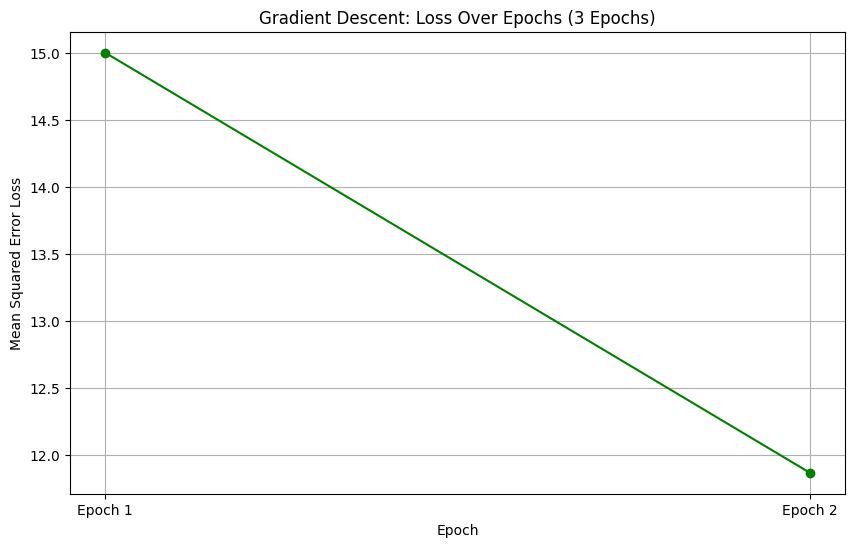

In [ ]:
# Visualize the loss over 3 epochs
plt.figure(figsize=(10, 6))
plt.plot(range(epochs_new), loss_history_new, color='green', marker='o')
plt.title('Gradient Descent: Loss Over Epochs (3 Epochs)')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error Loss')
plt.grid(True)
plt.xticks(range(epochs_new), [f'Epoch {i+1}' for i in range(epochs_new)])
plt.show()

## Gradient Descent for J(theta) = theta^3

In [ ]:
# Define the cost function J(theta) = theta^3
def cost_function(theta):
    return theta**3

# Define the derivative of the cost function dJ/d(theta) = 3 * theta^2
def derivative(theta):
    return 3 * theta**2

# Initial parameters
theta = 8.0
learning_rate = 0.1
iterations = 3

# History for visualization
theta_history = []
j_history = []

print(f"Initial theta: {theta}")


Initial theta: 8.0


In [ ]:
# Gradient Descent loop
for i in range(iterations):
    # Store current theta and cost
    theta_history.append(theta)
    j_history.append(cost_function(theta))

    # Calculate gradient
    grad = derivative(theta)

    # Update theta
    theta = theta - learning_rate * grad

    print(f"Iteration {i+1}/{iterations}: theta = {theta:.4f}, J(theta) = {cost_function(theta_history[-1]):.4f}, Gradient = {grad:.4f}")

print(f"\nFinal theta after {iterations} iterations: {theta:.4f}")
print(f"Final J(theta) after {iterations} iterations: {cost_function(theta):.4f}")


Iteration 1/3: theta = -11.2000, J(theta) = 512.0000, Gradient = 192.0000
Iteration 2/3: theta = -48.8320, J(theta) = -1404.9280, Gradient = 376.3200
Iteration 3/3: theta = -764.2013, J(theta) = -116443.0402, Gradient = 7153.6927

Final theta after 3 iterations: -764.2013
Final J(theta) after 3 iterations: -446296273.4323


### Visualization of Gradient Descent Path

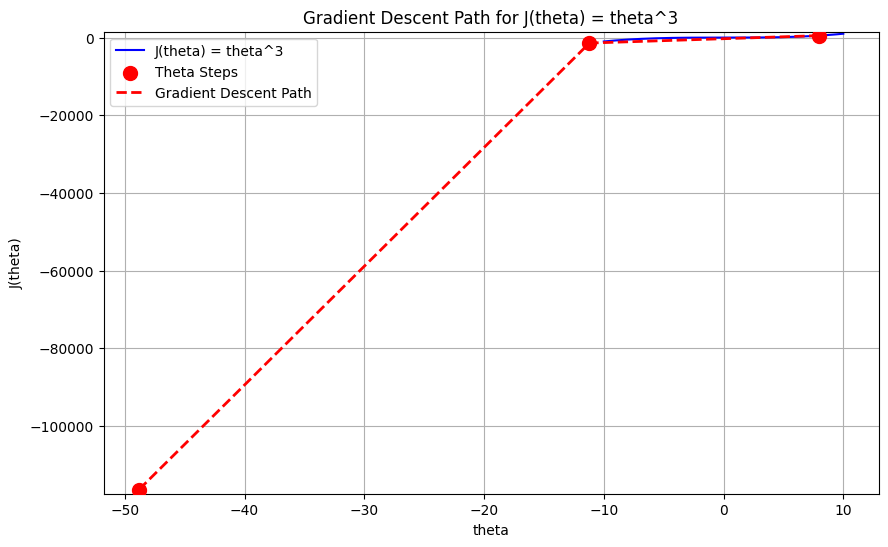

In [ ]:
# Generate values for plotting the cost function
theta_range = np.linspace(-10, 10, 400) # Adjust range as needed
j_range = cost_function(theta_range)

plt.figure(figsize=(10, 6))
plt.plot(theta_range, j_range, label='J(theta) = theta^3', color='blue')
plt.scatter(theta_history, j_history, color='red', s=100, zorder=5, label='Theta Steps')
plt.plot(theta_history, j_history, color='red', linestyle='--', linewidth=2, label='Gradient Descent Path')

plt.title('Gradient Descent Path for J(theta) = theta^3')
plt.xlabel('theta')
plt.ylabel('J(theta)')
plt.grid(True)
plt.legend()
plt.ylim(min(j_history) - 1000, max(j_history) + 1000) # Adjust y-limits for better visibility
plt.show()


### Visualization of Cost Over Iterations

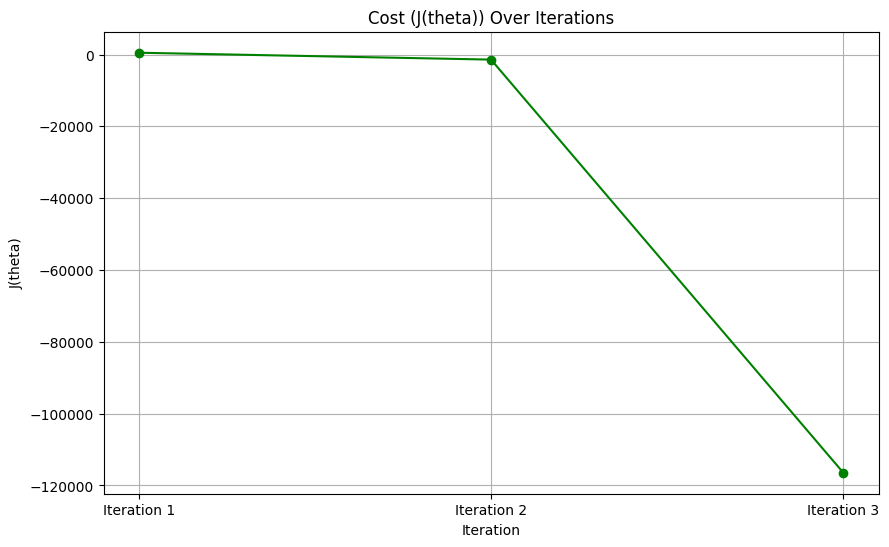

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(range(iterations), j_history, marker='o', color='green')
plt.title('Cost (J(theta)) Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('J(theta)')
plt.grid(True)
plt.xticks(range(iterations), [f'Iteration {i+1}' for i in range(iterations)])
plt.show()
